# Serie I: perfil de calidad y primera EDA

Este notebook perfila el CSV original sin modificarlo; el ETL aplica después las exclusiones analíticas. Separamos hallazgos descriptivos de decisiones de limpieza: algunas celdas fuente de `TRS_TON` tienen dos números y hay filas repetidas. El análisis conserva el texto original, separa el prefijo y usa solo el componente numérico final en la columna analítica `TRS_TON`.

La unidad de `T_SPACRE` se toma de la ficha oficial USDA-ARS (libras de azúcar por acre), según la decisión documentada al inicio del README.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 30)
pd.set_option('display.max_rows', 50)
sns.set_theme(style='whitegrid')

DATA_PATH = Path('../data/raw/louisiana_sugarcane_2010_2021.csv')
if not DATA_PATH.exists():
    DATA_PATH = Path('data/raw/louisiana_sugarcane_2010_2021.csv')
if not DATA_PATH.exists():
    raise FileNotFoundError('Descarga primero los datos con: python scripts/descargar_serie1.py')

# dtype=str y keep_default_na=False preservan literalmente marcadores y valores inusuales.
raw = pd.read_csv(DATA_PATH, dtype=str, keep_default_na=False)
print(f'Archivo: {DATA_PATH.as_posix()}')
print(f'Filas: {len(raw):,}; columnas: {len(raw.columns)}')
print(f'Columnas: {list(raw.columns)}')

Archivo: ../data/raw/louisiana_sugarcane_2010_2021.csv
Filas: 29,529; columnas: 15
Columnas: ['CLONE', 'YEAR', 'STAGE', 'LOC', 'CROP', 'REP', 'T_SPACRE', 'TRS_TON', 'TCA', 'POPN', 'MSTWT', 'FIBER', 'Unnamed: 12', 'Unnamed: 13', 'Unnamed: 14']


## 1. Marcadores, columnas auxiliares y repetidos

Los puntos y celdas vacías se reportan como aparecen en el archivo. Todavía no se imputan. Las tres columnas sin nombre se conservan en la lectura para no perder las seis notas al final del CSV.

In [2]:
marker_table = pd.DataFrame({
    'vacios': raw.apply(lambda col: col.str.strip().eq('').sum()),
    'punto': raw.apply(lambda col: col.str.strip().eq('.').sum()),
    'valores_distintos_no_vacios': raw.apply(lambda col: col.str.strip().ne('').sum()),
})
marker_table

,vacios,punto,valores_distintos_no_vacios
CLONE,0,0,29529
YEAR,0,0,29529
STAGE,0,0,29529
LOC,0,0,29529
CROP,0,0,29529
REP,0,0,29529
T_SPACRE,0,175,29529
TRS_TON,0,91,29529
TCA,0,166,29529
POPN,0,3533,29529


In [3]:
key = ['CLONE', 'YEAR', 'STAGE', 'LOC', 'CROP', 'REP']
measurement_cols = ['T_SPACRE', 'TRS_TON', 'TCA', 'POPN', 'MSTWT', 'FIBER']
exact_extra_rows = int(raw.duplicated().sum())
repeated_key_mask = raw.duplicated(key, keep=False)
key_groups = raw.loc[repeated_key_mask].groupby(key, dropna=False)[measurement_cols].nunique(dropna=False)
different_measure_groups = int((key_groups.gt(1).any(axis=1)).sum())
print(f'Filas completas repetidas (copias posteriores): {exact_extra_rows:,}')
print(f'Filas que pertenecen a grupos repetidos por clave candidata: {int(repeated_key_mask.sum()):,}')
print(f'Grupos de esa clave con mediciones distintas: {different_measure_groups:,}')
print('Este perfil conserva la fuente intacta; el ETL separa las copias exactas adicionales para el análisis.')

Filas completas repetidas (copias posteriores): 126
Filas que pertenecen a grupos repetidos por clave candidata: 476
Grupos de esa clave con mediciones distintas: 112
Este perfil conserva la fuente intacta; el ETL separa las copias exactas adicionales para el análisis.


## 2. Formato de `TRS_TON`

En la fuente aparecen dos patrones: un número simple y dos números separados por espacios. Conservamos el campo original en `TRS_TON_raw`, clasificamos el formato, aislamos el componente final en `TRS_TON` y guardamos el prefijo como texto sin interpretarlo. No se descarta ninguna parte del valor original.

In [4]:
trs_raw = raw['TRS_TON'].str.strip().replace({'': pd.NA, '.': pd.NA})
trs_parts = trs_raw.str.extract(r'^(?:(?P<prefijo>\d+)\s+)?(?P<componente_final>\d+(?:\.\d+)?)$')
profile = raw.copy()
profile['TRS_TON_raw'] = raw['TRS_TON']
profile['TRS_TON_prefijo_sin_interpretar'] = trs_parts['prefijo'].astype('string')
profile['TRS_TON'] = pd.to_numeric(trs_parts['componente_final'], errors='coerce')
profile['TRS_TON_formato'] = np.select(
    [profile['TRS_TON_prefijo_sin_interpretar'].notna(), profile['TRS_TON'].notna()],
    ['dos_componentes', 'numero_simple'], default='vacio_o_formato_no_reconocido'
)
print(profile['TRS_TON_formato'].value_counts(dropna=False).to_string())
print('Prefijos de texto sin interpretar:')
display(profile.loc[profile['TRS_TON_prefijo_sin_interpretar'].notna(), 'TRS_TON_prefijo_sin_interpretar'].value_counts().sort_index().to_frame('filas'))
print('Muestras del formato de dos componentes:')
display(profile.loc[profile['TRS_TON_formato'].eq('dos_componentes'), key + ['TRS_TON_raw', 'TRS_TON_prefijo_sin_interpretar', 'TRS_TON']].head(10))

TRS_TON_formato
numero_simple                    18953
dos_componentes                  10485
vacio_o_formato_no_reconocido       91
Prefijos de texto sin interpretar:


,filas
TRS_TON_prefijo_sin_interpretar,
00,114
01,111
02,112
03,114
04,89
...,...
95,113
96,115
97,109


Muestras del formato de dos componentes:


,CLONE,YEAR,STAGE,LOC,CROP,REP,TRS_TON_raw,TRS_TON_prefijo_sin_interpretar,TRS_TON
4564,L99-233,2010,4,AFH,0,2,79 227.620,79,227.620
4575,HOCP04-838,2017,3,AFL,0,2,58 262.506,58,262.506
4578,L99-233,2013,3,AFL,2,2,44 272.000,44,272.000
4580,L99-233,2012,3,STO,2,1,51 166.660,51,166.660
4581,L99-233,2013,4,BLK,2,1,69 241.000,69,241.000
4590,HOCP04-838,2016,3,MEL,2,2,43 294.492,43,294.492
4591,HOCP04-838,2016,3,STO,2,2,43 294.492,43,294.492
4595,L99-226,2016,4,BLK,2,1,14 237.782,14,237.782
4599,HOCP04-838,2016,3,AFL,0,1,00 258.160,00,258.160
4609,L99-233,2012,4,AFH,2,2,39 245.120,39,245.120


## 3. Coherencia dimensional

Comparamos `T_SPACRE` con `TCA × TRS_TON`, usando la columna analítica que contiene solo el componente numérico final. La operación evalúa si ese componente es coherente con la medición TRS: las unidades esperadas producen lb de azúcar/acre. La comparación sirve como control de coherencia, no aclara por sí sola qué representa el prefijo.

In [5]:
for col in ['T_SPACRE', 'TCA']:
    profile[f'{col}_num'] = pd.to_numeric(profile[col].replace({'': pd.NA, '.': pd.NA}), errors='coerce')
valid = (
    profile['T_SPACRE_num'].gt(0)
    & profile['TCA_num'].gt(0)
    & profile['TRS_TON'].gt(0)
)
check = profile.loc[valid, key + ['TRS_TON_raw', 'T_SPACRE_num', 'TCA_num', 'TRS_TON']].copy()
check['ratio_observado_esperado'] = check['T_SPACRE_num'] / (check['TCA_num'] * check['TRS_TON'])
check['dentro_1_por_ciento'] = check['ratio_observado_esperado'].sub(1).abs().le(0.01)
print(f'Filas positivas completas: {len(check):,}')
print(f'Dentro de 1 %: {check["dentro_1_por_ciento"].sum():,} ({check["dentro_1_por_ciento"].mean():.2%})')
print(f'Mediana de ratio observado/esperado: {check["ratio_observado_esperado"].median():.6f}')
print('Filas fuera de tolerancia:')
display(check.loc[~check['dentro_1_por_ciento']].sort_values('ratio_observado_esperado').reset_index(names='fila_csv').head(30))

Filas positivas completas: 29,340
Dentro de 1 %: 29,317 (99.92%)
Mediana de ratio observado/esperado: 0.999975
Filas fuera de tolerancia:


,fila_csv,CLONE,YEAR,STAGE,LOC,CROP,REP,TRS_TON_raw,T_SPACRE_num,TCA_num,TRS_TON,ratio_observado_esperado,dentro_1_por_ciento
0,9154,L99-226,2013,2,SGH,1,1,19 205.500,14689.0,74.0,205.500,0.965937,False
1,9270,L01-299,2011,2,SGH,0,1,84 221.395,6875.0,32.1,221.395,0.967386,False
2,15085,20069610,2010,3,STG,2,2,220.79,343.0,1.6,220.790,0.970945,False
3,23629,HOCP00-950,2012,2,SGH,2,1,91 270.610,8713.0,33.1,270.610,0.972738,False
4,29521,HOCP00-950,2016,5,ALLAINS,1,3,02 313.714,706.0,2.3,313.714,0.978460,False
5,9824,HOCP00-950,2010,2,SGH,0,1,48 268.015,11176.0,42.3,268.015,0.985796,False
6,12320,L03-371,2013,2,SGH,1,1,30 202.000,7906.0,39.7,202.000,0.985859,False
7,6355,L99-226,2016,2,SGH,1,1,18 247.998,4720.0,19.3,247.998,0.986135,False
8,10988,HOCP96-540,2013,2,SGH,0,1,90 169.000,5506.0,33.0,169.000,0.987269,False
9,7408,L99-233,2011,2,SGH,1,1,11 204.405,6864.0,34.0,204.405,0.987659,False


## 4. Primera mirada a `CROP`

Las tablas describen el archivo tal como está, incluidos los repetidos. Se muestran los tamaños de grupo junto con las medianas para hacer visible el desbalance. Una tendencia por `CROP` no establece causalidad ni garantiza el mismo patrón para cada clon, etapa o localidad.

In [6]:
profile['CROP_num'] = pd.to_numeric(profile['CROP'], errors='coerce')
crop_summary = profile.groupby('CROP_num', dropna=False)['T_SPACRE_num'].agg(n='count', media='mean', mediana='median', desviacion='std').round(1)
display(crop_summary)
stage_crop_median = profile.pivot_table(index='CROP_num', columns='STAGE', values='T_SPACRE_num', aggfunc='median')
display(stage_crop_median.round(0))

,n,media,mediana,desviacion
CROP_num,,,,
0,12647,10494.0,10100.7,3214.6
1,8076,9628.1,9236.5,3497.5
2,6004,8350.8,7862.5,3198.0
3,2543,7045.0,6819.0,2501.7
4,84,6687.4,6772.5,2023.3


STAGE,2,3,4,5
CROP_num,,,,
0,14128.0,10865.0,10106.0,9181.0
1,11586.0,10530.0,8754.0,8420.0
2,12270.0,9598.0,7735.0,7126.0
3,NaN,8557.0,6918.0,6594.0
4,NaN,NaN,NaN,6772.0


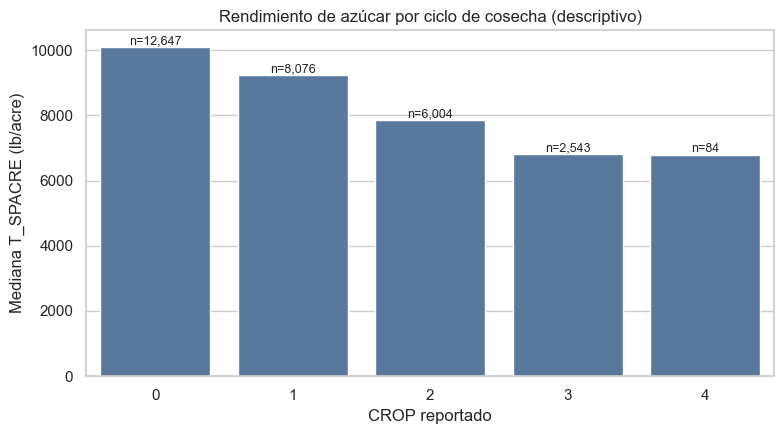

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.5))
plot_data = crop_summary.reset_index().dropna(subset=['CROP_num'])
sns.barplot(data=plot_data, x='CROP_num', y='mediana', color='#4C78A8', ax=ax)
for i, row in plot_data.reset_index(drop=True).iterrows():
    ax.text(i, row['mediana'], f"n={int(row['n']):,}", ha='center', va='bottom', fontsize=9)
ax.set(title='Rendimiento de azúcar por ciclo de cosecha (descriptivo)', xlabel='CROP reportado', ylabel='Mediana T_SPACRE (lb/acre)')
fig.tight_layout()

## Lectura provisional y decisiones para ETL

- La mediana de `T_SPACRE` desciende entre grupos `CROP=0` a `CROP=4`; el grupo 4 es pequeño y la cobertura por etapa es desigual. Analizar después estratos comparables y reportar sus tamaños.
- El valor fuente de `TRS_TON` contiene 10,485 celdas con dos componentes numéricos. El ETL conserva ese texto en `TRS_TON_raw`, separa el prefijo sin interpretarlo y deja el componente numérico final en `TRS_TON` para métricas y modelos.
- El ETL excluye las copias idénticas adicionales y las guarda con su motivo; la primera aparición se mantiene. Las filas con una clave candidata repetida y mediciones distintas permanecen para revisión hasta documentar la unidad experimental.
- `FIBER` tiene cobertura parcial importante. No imputar sin entender por qué falta y en qué etapas/localidades se mide.

La siguiente tarea es ampliar el EDA con métricas de cobertura, rangos y comparaciones justificadas. El ETL conserva columnas originales y campos derivados con trazabilidad; genera un dataset analítico sin copias exactas adicionales, un archivo separado de excluidos con motivo y un reporte de calidad.